# Open an example file

In [2]:
import warnings

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cm
import matplotlib.patches as mpatches
import matplotlib.path as mpath
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import pinner2026_jpo_code
import pinner2026_jpo_code.IO

# Suppress specific RuntimeWarning related to mean of empty slice
warnings.filterwarnings(action="ignore", category=RuntimeWarning, message=".*Mean of empty slice.*")

In [3]:
RAW_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "raw"
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"

In [2]:
# documentation at https://www.cen.uni-hamburg.de/en/icdc/data/cryosphere/seaicedrift-satobs-global.html
example = (
    RAW_DATA_DIR
    / "daily_sea_ice_drift/2017/NSIDC__SeaIceDrift__daily__25km__20170101__v04.1__UHH-ICDC_fv0.01.nc"
)
ds = xr.open_dataset(example, engine="netcdf4")
ds

<xarray.Dataset> Size: 5MB
Dimensions:        (y: 321, x: 321, time: 1)
Coordinates:
    lat            (y, x) float32 412kB ...
    lon            (y, x) float32 412kB ...
  * time           (time) datetime64[ns] 8B 2017-01-01
Dimensions without coordinates: y, x
Data variables:
    ux             (time, y, x) float32 412kB ...
    vy             (time, y, x) float32 412kB ...
    sigma          (time, y, x) float32 412kB ...
    u              (time, y, x) float32 412kB ...
    v              (time, y, x) float32 412kB ...
    velocity       (time, y, x) float32 412kB ...
    qualityflag_1  (time, y, x) float32 412kB ...
    qualityflag_2  (time, y, x) float32 412kB ...
    land           (time, y, x) float32 412kB ...
Attributes: (12/29)
    Conventions:                CF-1.6
    title:                      Daily gridded sea ice motion from combined Bu...
    source:                     Tschudi, M., W. N. Meier, J. S. Steward, C. F...
    history:                    Modified from source (see above) on Mon Apr 2...
    cdm_data_type:              EASE grid
    geographic_region:          polar regions
    ...                         ...
    geospatial_lon_resolution:  25km
    geospatial_lat_resolution:  25km
    platform:                   NOAA-Pathfinder NIMBUS DMSP
    sensor:                     AVHRR SMMR SSM/I SSMIS
    version:                    4.1
    citation:                   [1] Tschudi, M. A., Meier, W. N., and Stewart...

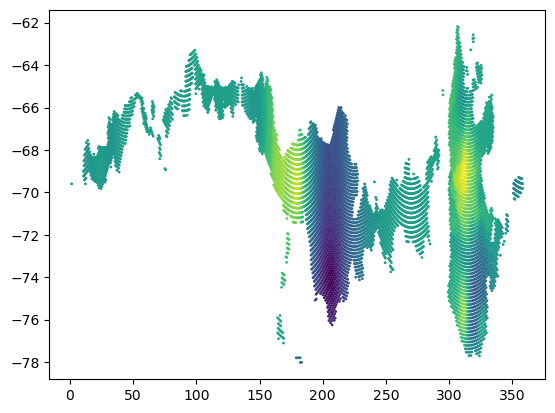

In [3]:
plt.scatter(ds.u.lon.values.flatten(), ds.u.lat.values.flatten(), c=ds.u.values.flatten(), s=1);

In [4]:
mooring_names = ["A", "B", "C", "D", "E", "F", "G"]
list_of_moorings = src.helper.load_pickle(name="../data/mooring/list_of_moorings.pkl")

In [5]:
def setup_Weddell_Sea(fig):

    # Define the projection for a high-resolution South Polar Stereographic map
    high_res_proj = ccrs.SouthPolarStereo(central_longitude=-50)
    high_res_proj.threshold = 1e3

    ax = fig.add_subplot(111, projection=high_res_proj)
    ax.add_feature(cfeature.LAND, color="grey")

    # Define the limits for the x-axis and y-axis of the map
    xlim = [-80, -20]  # longitude
    ylim = [-60, -80]  # latitude

    # Define a rectangular path for the map extent using matplotlib's Path object
    rect = mpath.Path(
        [
            [xlim[0], ylim[0]],
            [xlim[1], ylim[0]],
            [xlim[1], ylim[1]],
            [xlim[0], ylim[1]],
            [xlim[0], ylim[0]],
        ]
    )

    # Transform the rectangular path to the data coordinate system
    proj_to_data = ccrs.PlateCarree()._as_mpl_transform(ax) - ax.transData
    rect_in_target = proj_to_data.transform_path(rect)

    # Set the boundary of the map using the transformed rectangular path
    ax.set_boundary(rect_in_target)

    # Configure gridlines for the map
    gl = ax.gridlines(draw_labels=["top", "right", "x", "y"], rotate_labels=True, x_inline=False)

    # Draw latitude and longitude gridlines (and their labels)
    # only at the specified values
    # lathelp = np.arange(-75, -60, 5)
    # gl.ylocator = mticker.FixedLocator(lathelp)
    # lonhelp = np.arange(-80, -10, 10)
    # gl.xlocator = mticker.FixedLocator(lonhelp)

    # Rotate the longitude labels to be more readable
    gl.xlabel_style = {"rotation": 30}

    # To make sure that all of the wanted map extent is visible in the figure,
    # (especially because the chosen map projections differs strongly
    # at the poles from the PlateCarree Projection)
    # this hack of adding a constant is needed and may need be adjusted,
    # dependent on your map extent and figure size
    ax.set_extent([xlim[0], xlim[1], ylim[0] + 4, ylim[1]])

    return ax

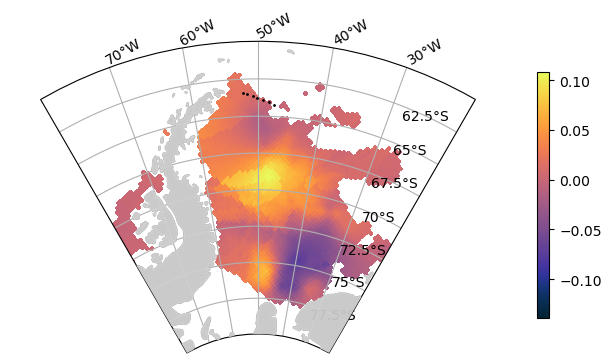

In [6]:
fig = plt.figure(figsize=(8, 8))
ax = setup_Weddell_Sea(fig)
im = ax.pcolormesh(
    ds.u.lon.values,
    ds.u.lat.values,
    np.squeeze(ds.u.values),
    transform=ccrs.PlateCarree(),
    cmap=cm.cm.thermal,
    shading="nearest",
)
ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)
# ax.contour(lon, lat, depth, transform=ccrs.PlateCarree(), levels = np.linspace(-5000,0,5), colors = "k", linestyles = "solid")
plt.colorbar(im, orientation="vertical", shrink=0.4)
for name, mooring in zip(mooring_names, list_of_moorings):
    ax.plot(mooring.location.lon, mooring.location.lat, "k.", ms=2, transform=ccrs.PlateCarree())

In [7]:
width_in_lon = 1
height_in_lat = 0.5

mooring_bins = {}
for name, mooring in zip(mooring_names, list_of_moorings):
    boxlats = np.array(
        [mooring.location.lat + height_in_lat / 2, mooring.location.lat - height_in_lat / 2]
    )
    boxlons = np.array(
        [mooring.location.lon - width_in_lon / 2, mooring.location.lon + width_in_lon / 2]
    )
    mooring_bins[name] = {"lat": boxlats, "lon": boxlons}

In [30]:
def setup_transect_view(fig):
    ax = fig.add_subplot(111, projection=ccrs.SouthPolarStereo(central_longitude=-50))
    # Limit the map to -60 degrees latitude and below.
    ax.set_extent([-54, -46, -64.5, -62.6], crs=ccrs.PlateCarree())
    # ax.set_extent([-55, -45, -65, -62], ccrs.PlateCarree())
    ax.gridlines(draw_labels=True)
    return ax

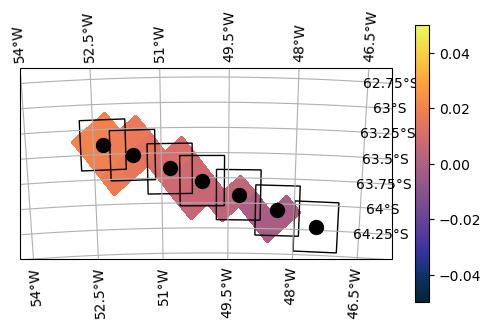

In [13]:
fig = plt.figure(figsize=(6, 6))
ax = setup_transect_view(fig)

ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)

for name, bounds in mooring_bins.items():
    mask = (
        (ds.lat >= bounds["lat"][1])
        & (ds.lat <= bounds["lat"][0])
        & (ds.lon >= 360 + bounds["lon"][0])
        & (ds.lon <= 360 + bounds["lon"][1])
    )

    icedrift_u_at_mooring = ds.u.where(mask, drop=True)
    icedrift_v_at_mooring = ds.v.where(mask, drop=True)

    boxlat = icedrift_u_at_mooring.lat  # latitude grid points
    boxlon = icedrift_u_at_mooring.lon  # longitude grid points

    assert boxlat.size != 1
    assert boxlon.size != 1

    im = ax.pcolormesh(
        boxlon - 360,
        boxlat,
        np.squeeze(icedrift_u_at_mooring.values),
        vmin=-0.05,
        vmax=0.05,
        transform=ccrs.PlateCarree(),
        cmap=cm.cm.thermal,
        shading="nearest",
    )

for name, mooring in zip(mooring_names, list_of_moorings):
    ax.plot(mooring.location.lon, mooring.location.lat, "k.", ms=20, transform=ccrs.PlateCarree())

for mooring in list_of_moorings:
    patch = mpatches.Rectangle(
        xy=[mooring.location.lon - width_in_lon / 2, mooring.location.lat - height_in_lat / 2],
        width=width_in_lon,
        height=height_in_lat,
        facecolor="none",
        edgecolor="k",
        transform=ccrs.PlateCarree(),
    )
    assert np.all(patch.get_center() == (mooring.location.lon, mooring.location.lat))
    ax.add_patch(patch)

plt.colorbar(im, shrink=0.6)

# load all files

In [3]:
filepaths = sorted(
    src.helper.get_filepaths_from_directory(
        "/media/sf_VM_Folder/data/DailySeaIceDrift/", inclusive=".nc"
    )
)
print(f"{len(filepaths)} files found")

730 files found


In [4]:
from functools import partial


def _preprocess(x, lon_bnds, lat_bnds):
    subset = x.where(
        (x.lat >= lat_bnds[0])
        & (x.lat <= lat_bnds[1])
        & (x.lon >= lon_bnds[0])
        & (x.lon <= lon_bnds[1]),
        drop=True,
    )
    return subset


lon_bnds, lat_bnds = (360 - 70, 360 - 30), (-80, -60)
partial_func = partial(_preprocess, lon_bnds=lon_bnds, lat_bnds=lat_bnds)

In [9]:
sea_ice_drift = xr.open_mfdataset(
    filepaths,
    # combine='nested',
    # concat_dim="time",
    # preprocess=partial_func,
    drop_variables=["ux", "vy", "velocity", "sigma", "qualityflag_1", "qualityflag_2", "land"],
    engine="netcdf4",
)

In [22]:
sea_ice_drift.nbytes

602589608

In [8]:
mooring_names = ["A", "B", "C", "D", "E", "F", "G"]
list_of_moorings = src.helper.load_pickle(name="../data/mooring/list_of_moorings.pkl")
width_in_lon = 1
height_in_lat = 0.5

mooring_bins = {}
for name, mooring in zip(mooring_names, list_of_moorings):
    boxlats = np.array(
        [mooring.location.lat + height_in_lat / 2, mooring.location.lat - height_in_lat / 2]
    )
    boxlons = np.array(
        [mooring.location.lon - width_in_lon / 2, mooring.location.lon + width_in_lon / 2]
    )
    mooring_bins[name] = {"lat": boxlats, "lon": boxlons}

In [37]:
results = {}
for name, bounds in mooring_bins.items():
    mask = (
        (sea_ice_drift.lat >= bounds["lat"][1])
        & (sea_ice_drift.lat <= bounds["lat"][0])
        & (sea_ice_drift.lon >= 360 + bounds["lon"][0])
        & (sea_ice_drift.lon <= 360 + bounds["lon"][1])
    ).compute()
    subset = sea_ice_drift.where(mask, drop=True)
    drift_at_mooring = subset.mean(dim=["x", "y"])
    results[name] = drift_at_mooring.u.values + 1j * drift_at_mooring.v.values

In [38]:
daily_sea_ice_drift = pd.DataFrame(index=sea_ice_drift.time.values, data=results)
daily_sea_ice_drift

,A,B,C,D,E,F,G
2017-01-01,0.019414+0.002679j,0.016290+0.002922j,0.010915+0.002427j,0.006443+0.000599j,0.002570-0.000439j,-0.001870-0.001659j,NaN+ NaNj
2017-01-02,-0.009996+0.013758j,-0.008790+0.011152j,-0.005044+0.006209j,-0.002560+0.003073j,-0.000324+0.000381j,0.000331-0.000375j,NaN+ NaNj
2017-01-03,0.010296+0.017750j,0.012220+0.015518j,0.011529+0.012776j,0.008729+0.009839j,0.001700+0.004136j,0.000926+0.003485j,NaN+ NaNj
2017-01-04,-0.016967+0.045658j,-0.018102+0.047121j,-0.019221+0.047501j,-0.020402+0.045497j,-0.020777+0.041404j,-0.019143+0.033787j,NaN+ NaNj
2017-01-05,0.028618-0.035387j,0.029320-0.036479j,0.029399-0.036241j,0.028392-0.034049j,NaN+ NaNj,0.021084-0.025406j,NaN+ NaNj
...,...,...,...,...,...,...,...
2018-12-27,0.004475+0.023664j,0.004553+0.022726j,0.004260+0.022486j,0.003322+0.023602j,-0.000950+0.027431j,-0.013304+0.030067j,-0.023075+0.034797j
2018-12-28,NaN+ NaNj,0.017300-0.004220j,0.015386-0.007225j,0.016438-0.009298j,0.016145-0.013818j,0.018252-0.018568j,0.021551-0.025357j
2018-12-29,NaN+ NaNj,-0.003648-0.024486j,-0.010840-0.027812j,-0.010827-0.030730j,-0.006391-0.032701j,-0.002590-0.035259j,0.004272-0.035743j
2018-12-30,NaN+ NaNj,-0.044307-0.047253j,-0.052345-0.059162j,-0.055966-0.064043j,-0.062817-0.072927j,-0.070216-0.084097j,-0.078937-0.097765j


In [39]:
daily_sea_ice_drift.to_csv("./daily_sea_ice_drift.csv")  # na_rep = np.nan+1j*np.nan)

# Sanity Check

In [40]:
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.dates as mdates

In [14]:
cmap = plt.cm.viridis
number_of_moorings = len(list_of_moorings)
color_list = [cmap(i / number_of_moorings) for i in range(number_of_moorings)]
# color_list.append("xkcd:rose")
discrete_cmap = mcolors.LinearSegmentedColormap.from_list(
    "mooring_ids", color_list, N=number_of_moorings
)

In [15]:
sea_ice_concentrations = pd.read_csv("./daily_sea_ice_concentrations.csv")  # , index_col = 0)
# sea_ice_concentrations.rename = "months"
sea_ice_concentrations.set_index(pd.to_datetime(sea_ice_concentrations["Unnamed: 0"]), inplace=True)
sea_ice_concentrations.drop("Unnamed: 0", inplace=True, axis="columns")

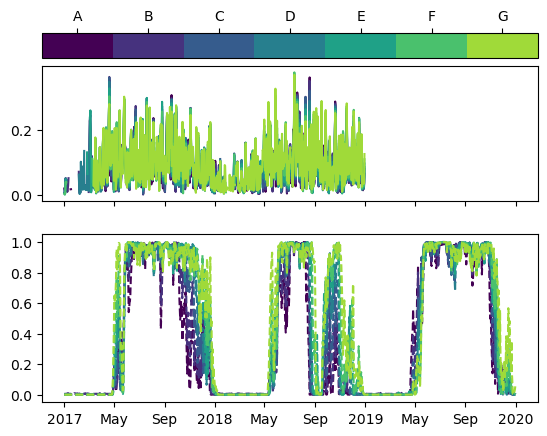

In [42]:
# fig, ax = plt.subplots(1)
# ax2 = plt.twinx(ax)

fig, axis = plt.subplots(nrows=2, sharex=True)
ax, ax2 = axis

for mooring_id, col in enumerate(daily_sea_ice_drift.columns):
    ax.plot(daily_sea_ice_drift.index, daily_sea_ice_drift[col].abs(), color=color_list[mooring_id])

for mooring_id, col in enumerate(sea_ice_concentrations.columns):
    ax2.plot(
        sea_ice_concentrations.index,
        sea_ice_concentrations[col],
        color=color_list[mooring_id],
        ls="--",
    )

norm = mcolors.Normalize(vmin=0, vmax=1)
cbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=discrete_cmap),
    ax=ax,
    location="top",
    orientation="horizontal",
)
cbar.ax.set_xticks(np.arange(0.5 / (number_of_moorings), 1, 1 / (number_of_moorings)))
cbar.ax.set_xticklabels(mooring_names)

ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.tick_params(axis="x", which="both", labelsize=7)